# Modelo substituto da turbina a gás com gás de síntese

**Autor** Hiago David Zogbi Silva Oliveira (LATERMO/UFF)

Este notebook reúne toda a etapa de aprendizado de máquina do TCC, a partir do banco de dados `data/dataset.csv` exportado pelo modelo termodinâmico em Wolfram Mathematica. As entradas são as condições operacionais $\mathbf{x}=[\dot m_f,\ \alpha,\ T_f,\ T_1]$ e as respostas são a eficiência térmica $\eta_{th}$, a geração de entropia $\dot S_{ger}$ e o índice de emissão de NOx $EI_{NO_x}$ (g de NOx, como NO$_2$, por kg de combustível). Para cada resposta é ajustado um modelo de saída única,

$$
\widehat{y}_j=\widehat{F}_{ML,j}(\mathbf{x};\mathbf{h}_j),
$$

e o modelo de menor erro de validação cruzada de cada resposta é exportado como função substituta.

| Seção | Conteúdo |
|---|---|
| 1 | Análise exploratória (correlações, diagrama de pares e divisão dos dados) |
| 2 | Comparação dos algoritmos com configurações de referência |
| 3 | Busca de hiperparâmetros (resultados dos códigos `train_*.py`) |
| 4 | Seleção e avaliação do modelo substituto |
| 5 | Desempenho em função do tamanho do banco |
| 6 | Exportação das funções substitutas |

As buscas de hiperparâmetros são demoradas e por isso rodam fora do notebook, nos códigos `train_LR.py`, `train_RF.py`, `train_GBT.py` e `train_NN.py`. As seções 3, 4 e 6 leem os resultados gravados em `results/` e são puladas enquanto eles não existem. A divisão treino/validação/teste (70/15/15, `random_state = 10`) é refeita em código por `tcc_ml.split`, idêntica em todos os códigos, e por isso nenhum arquivo de divisão é exportado.

## 0. Configuração

In [1]:
import warnings
warnings.filterwarnings('ignore')
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import re
import gc
import time
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import ticker
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
from scipy import stats
from sklearn import metrics
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

import tcc_ml as tm
from tcc_ml import LBL, SYM, COR, SET_C, ALG_C, DARK, fmt

tm.style(fs=15)
sns.set_theme(style='white', context='paper', rc=dict(mpl.rcParams))

SAVE = True                   # grava figuras (png 600 dpi e pdf) e tabelas em results/
REP = tm.OUT / 'Reports'
FIG = tm.OUT / 'Figures'
REP.mkdir(parents=True, exist_ok=True)

ALVOS = list(tm.T)            # eta_t, Sgen_kW_K, EINOx_g_kg
ALGS = ['LR', 'RF', 'GBT', 'NN1', 'NN2']
ALG_N = {'LR': 'RL', 'RF': 'RF', 'GBT': 'GBT', 'NN1': 'RNA', 'NN2': 'RNA'}    # rótulos nos gráficos
NM = {'tr': 'Treinamento', 'va': 'Validação', 'te': 'Teste', 'all': 'Todos'}
LOG = {'EINOx_g_kg'}          # respostas com eixos em escala log nos gráficos de paridade


def sv(fig, name, d=FIG):
    if SAVE:
        tm.savefig(fig, name, d)


df, F = tm.read_data()
D = {t: tm.split(df, F, t) for t in ALVOS}
print(f'{len(df)} registros válidos, entradas {F}')
for t in ALVOS:
    print(f"  {t:11s} treino {len(D[t]['ytr'])}, validação {len(D[t]['yva'])}, teste {len(D[t]['yte'])}")

8500 registros válidos, entradas ['mf_kg_s', 'alpha', 'Tf_K', 'Tar_K']
  eta_t       treino 5950, validação 1275, teste 1275
  Sgen_kW_K   treino 5950, validação 1275, teste 1275
  EINOx_g_kg  treino 5950, validação 1275, teste 1275


## 1. Análise exploratória

O banco foi gerado por um planejamento fatorial das entradas, seguido de um filtro de mapa que remove as combinações cuja vazão de ar sai do domínio do compressor. Como $\dot m_{ar}=\alpha\,\dot m_f\,(A/F)_{st}$, o filtro induz correlação entre $\dot m_f$ e $\alpha$ (e $H_2/CO$, quando essa razão é variada), enquanto $T_f$ e $T_{1}$ permanecem praticamente não correlacionadas com as demais entradas. As entradas são lidas do próprio CSV (todas as colunas fora das respostas).

In [2]:
cols = F + ALVOS
nm = {c: SYM.get(c, c) for c in cols}
d = df[cols]
if 'H2_CO' in F:
    print('Níveis de H2/CO', np.round(np.sort(df['H2_CO'].unique()), 4))
d.describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
mf_kg_s,8500.0,3.1412,1.9710,1.0000,1.7778,2.5556,4.1111,8.0000
alpha,8500.0,2.1297,1.3293,0.3042,0.9167,1.9375,3.1625,5.0000
Tf_K,8500.0,544.1000,163.3467,288.2000,401.9333,544.1000,686.2667,800.0000
Tar_K,8500.0,293.1500,15.9581,268.1500,279.2611,293.1500,307.0389,318.1500
eta_t,8500.0,0.2074,0.1073,0.0188,0.1161,0.1967,0.3044,0.4158
Sgen_kW_K,8500.0,17.2424,5.6904,7.2522,13.2369,16.5781,21.0327,36.3128
EINOx_g_kg,8500.0,5.3138,5.1457,0.0000,0.8660,3.3639,9.7042,20.6711


### 1.1 Correlações

A associação linear é medida pelo coeficiente de Pearson e a associação monotônica pelo coeficiente de Spearman, calculado sobre os postos $R$ das variáveis,

$$
\rho_{S,jk}=\frac{\operatorname{Cov}(R_j,R_k)}{\sigma_{R_j}\,\sigma_{R_k}} .
$$

Diferenças entre os dois coeficientes indicam relações monotônicas não lineares.

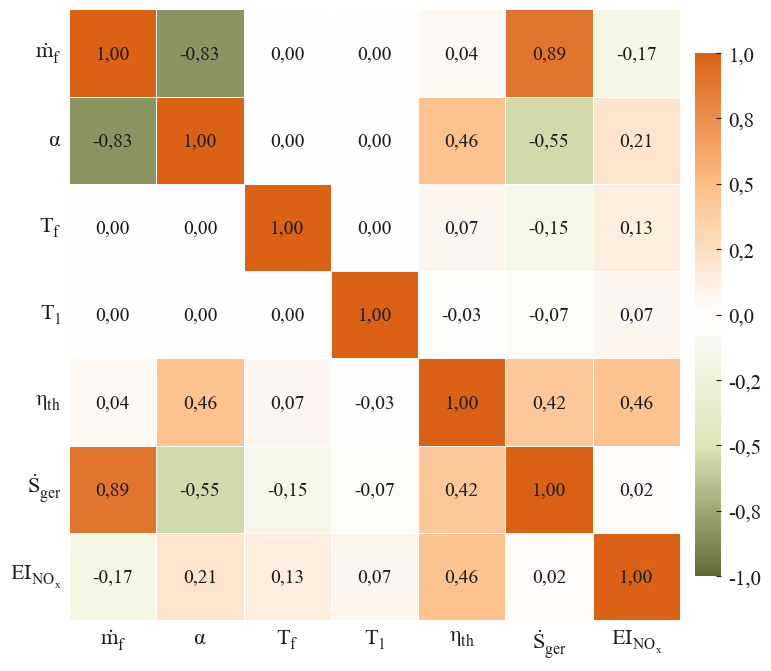

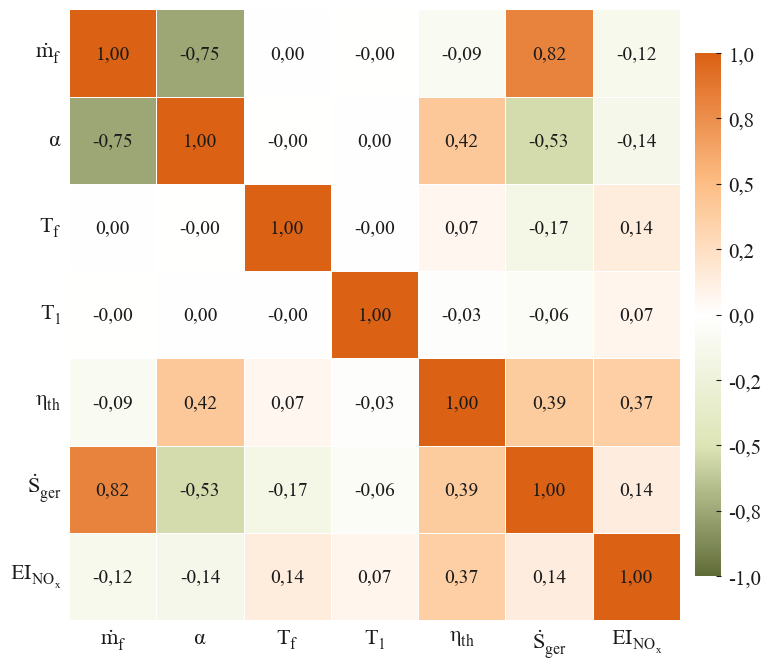

In [3]:
METADE = False        # True = só o triângulo inferior | False = matriz completa

CDIV = LinearSegmentedColormap.from_list('earth_div', ['#606C38', '#DDE5B6', '#FFFFFF', tm.ACCENT, tm.PRIM])
φ = lambda x, k=2: f'{x:.{k}f}'.replace('.', ',')          # número com vírgula decimal

Cp = d.corr('pearson').rename(index=nm, columns=nm)
Cs = d.corr('spearman').rename(index=nm, columns=nm)
if SAVE:
    (REP / 'EDA').mkdir(parents=True, exist_ok=True)
    Cs.to_csv(REP / 'EDA' / 'spearman.csv')
    Cp.to_csv(REP / 'EDA' / 'pearson.csv')


def heat(Cm, name):
    n = len(Cm)
    fig, a = plt.subplots(figsize=(0.95 * n + 1.6, 0.85 * n + 1.2))
    msk = np.triu(np.ones_like(Cm, bool), k=1) if METADE else None
    sns.heatmap(Cm, mask=msk, annot=np.vectorize(φ)(Cm.values), fmt='', cmap=CDIV, vmin=-1, vmax=1, center=0,
                square=True, linewidths=0.6, linecolor='white', cbar_kws={'shrink': 0.8, 'pad': 0.02},
                annot_kws={'size': 14 if n <= 7 else 12, 'color': DARK}, ax=a)
    a.collections[0].colorbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: φ(x, 1)))
    a.tick_params(length=0, labelsize=16)
    plt.setp(a.get_yticklabels(), rotation=0)
    plt.tight_layout()
    sv(fig, name, FIG / 'EDA')
    plt.show()


heat(Cs, 'spearman')
heat(Cp, 'pearson')

### 1.2 Diagramas de dispersão entre pares

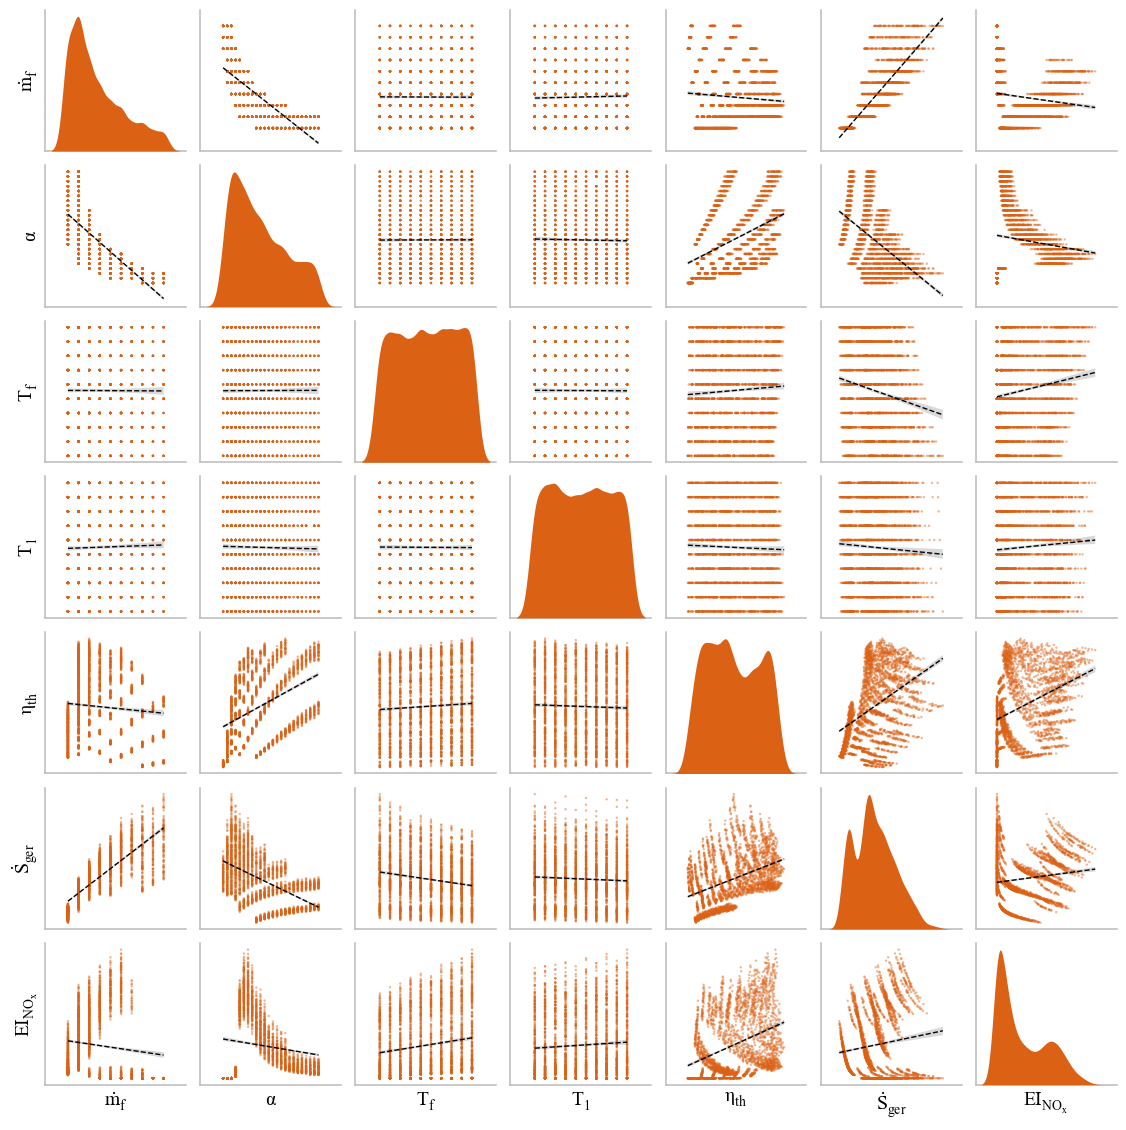

In [4]:
N_PAIR = 3000        # amostras desenhadas (None = todas)
pp = (d.sample(N_PAIR, random_state=tm.SEED) if N_PAIR else d).rename(columns=nm)

g = sns.PairGrid(pp, height=1.7, diag_sharey=False)
# fora da diagonal, pontos com reta de regressão tracejada e banda de confiança de 95 %
g.map_offdiag(sns.regplot, color=tm.GRAY, ci=95, n_boot=200, truncate=True,
              scatter_kws=dict(s=3, alpha=0.45, color=tm.PRIM, edgecolor='none'),
              line_kws=dict(color='black', ls='--', lw=1.0))
# na diagonal, a densidade de cada variável
g.map_diag(sns.kdeplot, fill=True, color=tm.PRIM, alpha=1.0, linewidth=0, warn_singular=False)

for a in g.axes.flat:
    a.set_xticks([])
    a.set_yticks([])
    a.spines[['top', 'right']].set_visible(False)
    a.spines[['left', 'bottom']].set_color('#BBBBBB')
    a.xaxis.label.set_size(14)
    a.yaxis.label.set_size(14)
g.fig.subplots_adjust(wspace=0.1, hspace=0.1)
sv(g.fig, 'pairplot', FIG / 'EDA')
plt.show()

### 1.3 Divisão dos dados (60/20/20)

O teste recebe 20 % do total e a validação $20%$ do restante, com `random_state = 10`. A tabela compara a média (desvio padrão) de cada variável nos três conjuntos, o que confirma que todos cobrem o mesmo domínio.

In [5]:
itr, iva, ite = tm.idx(len(df))
S0 = {'Treinamento': itr, 'Validação': iva, 'Teste': ite}
print({k: len(j) for k, j in S0.items()})

μ = pd.DataFrame({k: d.iloc[j].mean() for k, j in S0.items()}).rename(index=nm)
σ = pd.DataFrame({k: d.iloc[j].std() for k, j in S0.items()}).rename(index=nm)
display(μ.round(4).astype(str) + ' (' + σ.round(4).astype(str) + ')')
if 'H2_CO' in F:                       # contagem por nível de H2/CO em cada conjunto
    display(pd.DataFrame({k: d.iloc[j]['H2_CO'].round(4).value_counts().sort_index() for k, j in S0.items()}))

{'Treinamento': 5950, 'Validação': 1275, 'Teste': 1275}


,Treinamento,Validação,Teste
$\dot{m}_f$,3.1404 (1.9679),3.1735 (1.9682),3.1125 (1.9897)
$\alpha$,2.1404 (1.334),2.0965 (1.3083),2.1128 (1.3285)
$T_f$,544.5683 (162.7333),541.0002 (164.0075),545.0143 (165.6205)
$T_1$,293.1276 (15.9275),293.5313 (15.9497),292.8733 (16.1136)
$\eta_{th}$,0.2086 (0.1075),0.2083 (0.1047),0.2012 (0.1086)
$\dot{S}_{ger}$,17.253 (5.6563),17.4166 (5.7491),17.0186 (5.7866)
$EI_{NO_x}$,5.2911 (5.1103),5.4613 (5.2909),5.2722 (5.1646)


## 2. Comparação com configurações de referência

Antes da busca de hiperparâmetros, cada algoritmo é avaliado com uma configuração de referência sobre os mesmos dados e com a mesma validação cruzada de cinco partições. A comparação indica quais abordagens representam melhor as relações entre as condições operacionais e cada resposta do ciclo.

| Algoritmo | Configuração de referência |
|---|---|
| RL | mínimos quadrados ordinários |
| RF | 100 árvores, profundidade máxima 10, 5 amostras por folha, 10 por divisão, metade dos atributos |
| GBT | 100 árvores, $\nu=0{,}1$, profundidade 3 |
| RNA | 1 camada com 60 neurônios ReLU, Adam com $\eta=10^{-3}$, lote 32, até 400 épocas com interrupção antecipada |

In [6]:
REFAZER = False       # True recalcula | False lê Reports/referencia.csv quando existir
f_ref = REP / 'referencia.csv'
f_pr = REP / 'referencia_pred_teste.npz'      # previsões no teste (unidades físicas)


def ref_models():
    return {
        'LR': LinearRegression(),
        'RF': RandomForestRegressor(n_estimators=100, max_depth=10, min_samples_leaf=5,
                                    min_samples_split=10, max_features=0.5,
                                    random_state=tm.SEED, n_jobs=-1),
        'GBT': GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=tm.SEED),
        'NN1': MLPRegressor(hidden_layer_sizes=(60,), activation='relu', solver='adam',
                            learning_rate_init=1e-3, batch_size=32, max_iter=400,
                            early_stopping=True, validation_fraction=0.15, n_iter_no_change=20,
                            random_state=tm.SEED),
    }


if REFAZER or not f_ref.exists():
    rows, PR = [], {}
    for t in ALVOS:
        X, y = D[t]['Xtr'], D[t]['ytr_n'].ravel()
        for a, m in ref_models().items():
            t0 = perf_counter()
            est = Pipeline([('sx', MinMaxScaler()), ('m', m)])     # normalização reajustada em cada partição
            cv, _ = tm.cv5(est, X, y)
            est.fit(X, y)
            dt = perf_counter() - t0
            rows.append({'t': t, 'alg': a, **cv, **tm.aval(est.predict, D[t]), 'tempo_s': dt})
            PR[f'{t}|{a}'] = tm.inv(D[t], est.predict(D[t]['Xte']))
            print(f'{t:12s} {ALG_N[a]:4s} MSE_CV = {cv["cv_mse"]:.3e}  R2_CV = {cv["cv_r2"]:.4f}  ({dt:5.1f} s)')
    ref = pd.DataFrame(rows)
    ref.to_csv(f_ref, index=False)
    np.savez(f_pr, **PR)
else:
    ref = pd.read_csv(f_ref)
    PR = dict(np.load(f_pr)) if f_pr.exists() else {}
    print(f'Resultados lidos de {tm.rel(f_ref)}')

display(ref.pivot(index='alg', columns='t', values=['cv_mse', 'cv_r2', 'val_r2']).reindex(ALGS[:4]).round(5))
display(ref.pivot(index='alg', columns='t', values='tempo_s').reindex(ALGS[:4]).round(1))

eta_t        RL   MSE_CV = 5.226e-02  R2_CV = 0.2996  (  0.0 s)
eta_t        RF   MSE_CV = 5.123e-04  R2_CV = 0.9931  (  0.9 s)
eta_t        GBT  MSE_CV = 4.241e-04  R2_CV = 0.9943  (  1.0 s)
eta_t        RNA  MSE_CV = 1.527e-04  R2_CV = 0.9980  (  9.9 s)
Sgen_kW_K    RL   MSE_CV = 1.103e-02  R2_CV = 0.7170  (  0.0 s)
Sgen_kW_K    RF   MSE_CV = 3.141e-04  R2_CV = 0.9919  (  0.9 s)
Sgen_kW_K    GBT  MSE_CV = 1.556e-04  R2_CV = 0.9960  (  1.0 s)
Sgen_kW_K    RNA  MSE_CV = 2.282e-05  R2_CV = 0.9994  (  7.8 s)
EINOx_g_kg   RL   MSE_CV = 5.473e-02  R2_CV = 0.1632  (  0.0 s)
EINOx_g_kg   RF   MSE_CV = 2.723e-04  R2_CV = 0.9958  (  0.9 s)
EINOx_g_kg   GBT  MSE_CV = 1.867e-04  R2_CV = 0.9971  (  1.0 s)
EINOx_g_kg   RNA  MSE_CV = 5.094e-05  R2_CV = 0.9992  ( 15.1 s)


cv_mse                         cv_r2                        val_r2  \
t   EINOx_g_kg Sgen_kW_K    eta_t EINOx_g_kg Sgen_kW_K    eta_t EINOx_g_kg   
alg                                                                          
LR     0.05473   0.01103  0.05226    0.16321   0.71700  0.29959    0.17398   
RF     0.00027   0.00031  0.00051    0.99584   0.99195  0.99313    0.99562   
GBT    0.00019   0.00016  0.00042    0.99715   0.99601  0.99431    0.99653   
NN1    0.00005   0.00002  0.00015    0.99922   0.99941  0.99795    0.99942   

                        
t   Sgen_kW_K    eta_t  
alg                     
LR    0.72497  0.28073  
RF    0.99272  0.99341  
GBT   0.99641  0.99381  
NN1   0.99951  0.99806

t,EINOx_g_kg,Sgen_kW_K,eta_t
alg,,,
LR,0.0,0.0,0.0
RF,0.9,0.9,0.9
GBT,1.0,1.0,1.0
NN1,15.1,7.8,9.9


In [ ]:
def bars(dd, col, ylab, name, log=True, err=None):
    al = [a for a in ALGS if a in dd['alg'].unique()]
    fig, ax = plt.subplots(1, len(ALVOS), figsize=(5.6 * len(ALVOS), 4.2))
    for a_, t in zip(np.atleast_1d(ax), ALVOS):
        s = dd[dd['t'] == t].set_index('alg').reindex(al)
        a_.bar(range(len(al)), s[col], yerr=s[err].values if err else None, capsize=3,
               color=[ALG_C[k] for k in al], edgecolor=DARK, linewidth=0.6, width=0.65)
        a_.set_xticks(range(len(al)), [ALG_N[k] for k in al])
        a_.set_xlabel(SYM[t])
        if log:
            a_.set_yscale('log')
        tm.ticks(a_, minor=False)
    np.atleast_1d(ax)[0].set_ylabel(ylab)
    plt.tight_layout()
    sv(fig, name, FIG / 'Avaliacao')
    plt.show()


def parity_ref():
    """Valores previstos x valores de referência no teste, na escala normalizada do treino."""
    al = [a for a in ALGS if any(k.endswith('|' + a) for k in PR)]
    nr, nc = len(ALVOS), len(al)
    fig, ax = plt.subplots(nr, nc, figsize=(4.1 * nc, 4.1 * nr), squeeze=False)
    for i, t in enumerate(ALVOS):
        y = D[t]['yte_n'].ravel()
        for j, a in enumerate(al):
            a_ = ax[i, j]
            p = D[t]['sy'].transform(PR[f'{t}|{a}'].reshape(-1, 1)).ravel()
            a_.plot([0, 1], [0, 1], '-', color=DARK, lw=1.0)
            a_.scatter(y, p, s=7, color=ALG_C[a], alpha=0.6, edgecolor='none')
            a_.text(0.05, 0.92, rf'$R^2={tm.metr(y, p)["R2"]:.4f}$'.replace('.', '{,}'),
                    transform=a_.transAxes, fontsize=13)
            a_.set_xlim(0, 1)
            a_.set_ylim(0, 1)
            a_.set_aspect('equal')
            for ax_ in (a_.xaxis, a_.yaxis):
                ax_.set_major_locator(ticker.MultipleLocator(0.25))
                ax_.set_major_formatter(fmt(2))
            if i == 0:
                a_.set_title(ALG_N[a], fontsize=15)
            if j == 0:
                a_.set_ylabel(f'{SYM[t]} previsto normalizado')
            a_.set_xlabel(f'{SYM[t]} de referência normalizado')
            tm.ticks(a_)
    plt.tight_layout()
    sv(fig, 'referencia_paridade_teste', FIG / 'Avaliacao')
    plt.show()


bars(ref, 'cv_mse', r'$\overline{MSE}_{CV}$ (normalizado)', 'referencia_mse', err='cv_mse_std')
if PR:
    parity_ref()

## 3. Busca de hiperparâmetros

Cada código de treino é executado em duas etapas, pela linha de comando, a partir da pasta `python/`.

```bash
python train_GBT.py --cv                  # seleção por validação cruzada
python train_GBT.py --train --sel best    # treino final da melhor configuração
python train_RF.py  --cv && python train_RF.py --train --sel 5
python train_NN.py  --cv && python train_NN.py --train --sel best
python train_LR.py                        # referência, sem busca
```

Com `--cv`, todas as configurações $\mathbf{h}$ são avaliadas apenas por validação cruzada e o resultado fica em `results/Reports/<ALG>_<resposta>/CV/summary_cv.csv`, ordenado por $\overline{MSE}_{CV}$. A primeira linha é

$$
\mathbf{h}^*=\arg\min_{\mathbf{h}}\ \overline{MSE}_{CV}(\mathbf{h}),\qquad
\overline{MSE}_{CV}(\mathbf{h})=\frac{1}{5}\sum_{k=1}^{5}MSE_k(\mathbf{h}).
$$

Com `--train`, as configurações selecionadas são treinadas no conjunto de treinamento completo e avaliadas em validação e teste, e o resultado fica em `results/Reports/<ALG>_<resposta>/summary.csv`, com o caminho de cada modelo salvo.

In [ ]:
S, TR = {}, {}      # S = busca por validação cruzada | TR = modelos treinados
for t in ALVOS:
    for a in ALGS:
        r = REP / f'{a}_{t}'
        if (r / 'CV' / 'summary_cv.csv').exists():
            S[(a, t)] = pd.read_csv(r / 'CV' / 'summary_cv.csv')
        if (r / 'summary.csv').exists():
            TR[(a, t)] = pd.read_csv(r / 'summary.csv')
            S.setdefault((a, t), TR[(a, t)])

if not TR:
    print('Nenhum modelo treinado em results/Reports. Rode os códigos train_*.py (seção 3).')
else:
    for (a, t), s in S.items():
        print(f'  {a:4s} {t:12s} {len(s):5d} configurações na CV, {len(TR.get((a, t), [])):3d} treinadas')
    best = pd.DataFrame([{'t': t, 'alg': a, **(TR[(a, t)] if (a, t) in TR else s).iloc[0].to_dict()}
                         for (a, t), s in S.items()])
    c_ = ['t', 'alg', 'cv_mse', 'cv_mse_std', 'cv_r2', 'train_r2', 'val_r2', 'test_r2',
          'train_mse', 'val_mse', 'test_mse', 'time_s']
    best = best[[c for c in c_ if c in best]]
    best.to_csv(REP / 'melhores_por_algoritmo.csv', index=False)
    display(best.sort_values(['t', 'cv_mse']).round(6))

In [ ]:
if TR:
    bars(best, 'cv_mse', r'$\overline{MSE}_{CV}$ (normalizado)', 'melhores_mse',
         err='cv_mse_std' if 'cv_mse_std' in best else None)

    # panorama da busca, MSE_CV de cada configuração contra o MSE de validação
    fig, ax = plt.subplots(1, len(ALVOS), figsize=(6.0 * len(ALVOS), 5.2))
    for a_, t in zip(np.atleast_1d(ax), ALVOS):
        lo, hi = np.inf, -np.inf
        for a in ALGS:
            if (a, t) not in TR:
                continue
            s = TR[(a, t)]
            a_.scatter(s['cv_mse'], s['val_mse'], s=14, alpha=0.6, color=ALG_C[a], edgecolor='none', label=ALG_N[a])
            a_.scatter(s['cv_mse'].iloc[:1], s['val_mse'].iloc[:1], s=80, color=ALG_C[a], edgecolor=DARK,
                       linewidth=1.0, zorder=5)
            lo = min(lo, s[['cv_mse', 'val_mse']].min().min())
            hi = max(hi, s[['cv_mse', 'val_mse']].max().max())
        if np.isfinite(lo):
            a_.plot([lo, hi], [lo, hi], '--', color=DARK, lw=1.0)
        a_.set_xscale('log')
        a_.set_yscale('log')
        a_.set_xlabel(r'$\overline{MSE}_{CV}$')
        a_.set_ylabel(r'$MSE_{val}$')
        a_.text(0.04, 0.92, SYM[t], transform=a_.transAxes, fontsize=17)
        tm.ticks(a_, minor=False)
    np.atleast_1d(ax)[-1].legend(frameon=False, loc='lower right', markerscale=1.6)
    plt.tight_layout()
    sv(fig, 'panorama_busca', FIG / 'Avaliacao')
    plt.show()

### 3.1 Sensibilidade aos hiperparâmetros

Distribuição de $\overline{MSE}_{CV}$ para cada valor de cada hiperparâmetro. A mediana indica o efeito típico do hiperparâmetro sobre o erro, e a dispersão reflete a interação com os demais.

In [ ]:
HP = {
    'RF': ['n_estimators', 'max_depth', 'min_samples_split', 'min_samples_leaf', 'max_features'],
    'GBT': ['n_estimators', 'learning_rate', 'max_depth', 'min_samples_leaf', 'subsample'],
    'NN1': ['c1', 'lr', 'batch'],
    'NN2': ['c1', 'c2', 'lr', 'batch'],
}
HP_L = {'n_estimators': 'Árvores', 'max_depth': 'Profundidade máxima', 'min_samples_split': 'Amostras por divisão',
        'min_samples_leaf': 'Amostras por folha', 'max_features': 'Atributos por divisão',
        'learning_rate': r'Taxa de aprendizagem $\nu$', 'subsample': 'Fração de amostragem',
        'c1': 'Neurônios (camada 1)', 'c2': 'Neurônios (camada 2)', 'lr': 'Taxa de aprendizagem',
        'batch': 'Tamanho do lote'}


def _okey(z):
    try:
        return (0, float(z))
    except ValueError:
        m = re.match(r'[\(\[]\s*([-+0-9.eE]+)', z)
        return (0, float(m.group(1))) if m else (1, z)


def sens(a, t, nbin=8):
    s = S[(a, t)]
    hp = [h for h in HP[a] if h in s and s[h].nunique() > 1]
    if not hp:
        return
    fig, ax = plt.subplots(1, len(hp), figsize=(3.7 * len(hp), 3.8), sharey=True)
    for a_, h in zip(np.atleast_1d(ax), hp):
        v = s[h].astype(str).replace('nan', 'None')
        if s[h].dtype.kind in 'if' and s[h].nunique() > nbin:     # neurônios em faixas
            v = pd.cut(s[h], nbin).astype(str)
        k = sorted(v.unique(), key=_okey)
        bp = a_.boxplot([s.loc[v == z, 'cv_mse'].values for z in k], widths=0.55, patch_artist=True,
                        showfliers=False, medianprops=dict(color=DARK, lw=1.4))
        for b in bp['boxes']:
            b.set(facecolor=COR['all'], edgecolor=DARK, linewidth=0.8)
        rot = len(k) > 4
        a_.set_xticks(range(1, len(k) + 1), k, rotation=45 if rot else 0, ha='right' if rot else 'center')
        a_.set_xlabel(HP_L.get(h, h))
        a_.set_yscale('log')
        tm.ticks(a_, minor=False)
    np.atleast_1d(ax)[0].set_ylabel(r'$\overline{MSE}_{CV}$')
    plt.tight_layout()
    sv(fig, f'sensibilidade_{a}_{t}', FIG / 'Avaliacao')
    plt.show()


for t in ALVOS:
    for a in ['RF', 'GBT', 'NN1', 'NN2']:
        if (a, t) in S:
            print(f'{a} — {t}')
            sens(a, t)

## 4. Seleção do modelo substituto

A seleção é feita separadamente para cada resposta. Por padrão é escolhido o modelo de menor $\overline{MSE}_{CV}$ entre todos os algoritmos treinados. Para fixar outra escolha (por exemplo, um modelo suave para a otimização com refinamento por gradiente), indique o algoritmo e a posição no ranking em `SEL`.

In [ ]:
SEL = {
    'eta_t': None,          # None = melhor MSE_CV global | ('NN1', 0) = algoritmo e posição no ranking
    'Sgen_kW_K': None,
    'EINOx_g_kg': None,
}


def pick(t, sel=None):
    if sel is None:
        c = [(TR[(a, t)]['cv_mse'].iloc[0], a) for a in ALGS if (a, t) in TR]
        a, k = min(c)[1], 0
    else:
        a, k = sel
    s = TR[(a, t)]
    if 'file' not in s or pd.isna(s.loc[k, 'file']):
        raise ValueError(f'O modelo {a} posição {k} não foi treinado. Rode o código com --train.')
    return a, s.loc[k, 'file']


M = {}
for t in ALVOS:
    if not any((a, t) in TR for a in ALGS):
        print(f'{t:10s} sem modelos treinados')
        continue
    a, p = pick(t, SEL.get(t))
    M[t] = tm.Sur(p)
    print(f'{t:10s} -> {a:4s} {tm.absp(p).name}')
    print(f'{"":14s}h* = {M[t].b["h"]}')
TS = [t for t in ALVOS if t in M]       # respostas com modelo selecionado

### 4.1 Métricas em unidades físicas

São apresentadas as métricas MSE, RMSE, MAE, MAPE e $R^2$ em cada conjunto. O MAPE é calculado apenas para $|y_i|\geq0{,}05\max|y|$, o que exclui valores de referência próximos de zero (caso de $\eta_{th}$ em misturas muito ricas e de $EI_{NO_x}$ com $\alpha<1$).

In [ ]:
P = {}
for t in TS:
    P[t] = {k: (D[t][f'y{k}'].ravel(), M[t](D[t][f'X{k}'])) for k in ('tr', 'va', 'te')}
    P[t]['all'] = tuple(np.concatenate([P[t][k][i] for k in ('tr', 'va', 'te')]) for i in (0, 1))

if TS:
    met_fis = pd.DataFrame([{'Resposta': t, 'Conjunto': NM[k], **tm.metr(*P[t][k])}
                            for t in TS for k in ('tr', 'va', 'te', 'all')])
    met_fis.to_csv(REP / 'metricas_modelo_selecionado.csv', index=False)
    display(met_fis.set_index(['Resposta', 'Conjunto']).style.format('{:.4e}', subset=['MSE', 'RMSE', 'MAE'])
            .format('{:.5f}', subset=['R2']).format('{:.3f}', subset=['MAPE']))

    # métricas de teste do melhor modelo de cada algoritmo (tabela comparativa)
    rows = []
    for t in TS:
        for a in ALGS:
            if (a, t) not in TR or 'file' not in TR[(a, t)] or pd.isna(TR[(a, t)].loc[0, 'file']):
                continue
            s_ = tm.Sur(TR[(a, t)].loc[0, 'file'])
            rows.append({'Resposta': t, 'Algoritmo': ALG_N[a], **tm.metr(D[t]['yte'], s_(D[t]['Xte'])),
                         'MSE_CV': TR[(a, t)].loc[0, 'cv_mse']})
    comp = pd.DataFrame(rows)
    comp.to_csv(REP / 'comparacao_teste_fisico.csv', index=False)
    display(comp.set_index(['Resposta', 'Algoritmo']).round(6))

### 4.2 Valores previstos e resíduos em unidades físicas

A concordância com a reta $\widehat{y}=y$ é avaliada para cada conjunto. Os resíduos são definidos por $e_i=y_i-\widehat{y}_i$, de modo que resíduos positivos indicam subestimação. Uma dispersão aleatória em torno de zero, sem tendência com $\widehat{y}$, é esperada para um modelo sem viés.

In [ ]:
def parity(t):
    fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.9))
    y_all = P[t]['all'][0]
    L = t in LOG
    if L:                                   # EI_NOx varia ordens de grandeza
        yp = y_all[y_all > 0]
        lim = [yp.min() / 1.5, yp.max() * 1.5]
    else:
        lim = [y_all.min(), y_all.max()]
        pad = 0.04 * (lim[1] - lim[0])
        lim = [lim[0] - pad, lim[1] + pad]
    for a_, k in zip(ax, ('tr', 'va', 'te')):
        y, p = P[t][k]
        a_.plot(lim, lim, '-', color=DARK, lw=1.1)
        a_.scatter(y, p, s=9, color=COR[k], alpha=0.7, edgecolor='none')
        a_.text(0.05, 0.93, NM[k], transform=a_.transAxes, fontsize=15)
        a_.text(0.05, 0.84, rf'$R^2={tm.metr(y, p)["R2"]:.4f}$'.replace('.', '{,}'), transform=a_.transAxes, fontsize=14)
        if L:
            a_.set_xscale('log')
            a_.set_yscale('log')
        a_.set_xlim(lim)
        a_.set_ylim(lim)
        a_.set_xlabel(f'{LBL[t]}  modelo termodinâmico')
        if not L:
            a_.xaxis.set_major_locator(ticker.MaxNLocator(5))
            a_.yaxis.set_major_locator(ticker.MaxNLocator(5))
        tm.ticks(a_)
    ax[0].set_ylabel(f'{LBL[t]}  modelo substituto')
    plt.tight_layout()
    sv(fig, f'paridade_{t}', FIG / 'Avaliacao')
    plt.show()


def resid(t):
    fig, ax = plt.subplots(1, 4, figsize=(19, 4.4), gridspec_kw={'width_ratios': [1, 1, 1, 0.8]})
    r = np.abs(P[t]['all'][0] - P[t]['all'][1]).max() * 1.05
    for a_, k in zip(ax[:3], ('tr', 'va', 'te')):
        y, p = P[t][k]
        a_.axhline(0, color=DARK, lw=1.1, ls='--')
        a_.scatter(p, y - p, s=8, color=COR[k], alpha=0.7, edgecolor='none')
        if t in LOG:
            a_.set_xscale('symlog', linthresh=0.1)
        a_.set_ylim(-r, r)
        a_.set_xlabel(f'{LBL[t]}  previsto')
        a_.text(0.04, 0.92, NM[k], transform=a_.transAxes, fontsize=14)
        tm.ticks(a_)
    ax[0].set_ylabel(r'Resíduo $e=y-\widehat{y}$')
    e = P[t]['te'][0] - P[t]['te'][1]
    zz = np.linspace(-r, r, 300)
    ax[3].hist(e, bins=40, density=True, color=COR['all'], edgecolor=DARK, linewidth=0.4, orientation='horizontal')
    ax[3].plot(stats.norm.pdf(zz, e.mean(), e.std()), zz, color=COR['tr'], lw=1.8)
    ax[3].set_ylim(-r, r)
    ax[3].set_xlabel('Densidade (teste)')
    ax[3].set_yticklabels([])
    tm.ticks(ax[3])
    plt.tight_layout()
    sv(fig, f'residuos_{t}', FIG / 'Avaliacao')
    plt.show()
    print(f'{t}: resíduo de teste com média {e.mean():.3e} e desvio {e.std():.3e}')


for t in TS:
    parity(t)
    resid(t)

### 4.3 Curvas de aprendizagem

Para as RNAs são apresentados o $R^2$ e o MSE (escala normalizada) ao longo das épocas e, para o GBT, ao longo do número de árvores adicionadas, nos conjuntos de treinamento e validação. No GBT o coeficiente de determinação é obtido de $R^2=1-MSE/\operatorname{Var}(y)$. A separação entre as curvas indica o grau de sobreajuste. RF e RL não possuem treinamento iterativo.

In [ ]:
def curvas(t):
    s = M[t]
    h = s.b.get('hist') or {}
    if 'loss' not in h:
        print(f'{t}: {s.alg} não possui treinamento iterativo')
        return
    mse = {c: np.asarray(h[k]) for c, k in (('tr', 'loss'), ('va', 'val_loss'))}
    k = next((c for c in h if 'r2' in c.lower() and not c.startswith('val')), None)
    if k:                                   # RNA, R2 registrado pelo Keras
        r2 = {'tr': np.asarray(h[k]), 'va': np.asarray(h['val_' + k])}
    else:                                   # GBT, R2 = 1 - MSE/Var(y)
        r2 = {c: 1 - mse[c] / np.var(D[t][f'y{c}_n']) for c in ('tr', 'va')}
    ep = np.arange(1, len(mse['tr']) + 1)

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    for a_, v, yl in zip(ax, (r2, mse), (r'$R^2$', 'MSE (normalizado)')):
        a_.plot(ep, v['tr'], '-', color=DARK, lw=1.3, label=NM['tr'])
        a_.plot(ep, v['va'], '--', color=COR['tr'], lw=1.3, label=NM['va'])
        a_.set_xlabel('Época' if s.alg.startswith('NN') else 'Número de árvores')
        a_.set_ylabel(yl)
        a_.set_xlim(0, ep[-1] * 1.03)
        a_.grid(True, color='#E6E6E6', lw=0.6)
        a_.tick_params(direction='in', top=True, right=True)
    ax[0].set_ylim(min(0.9, r2['va'][-1] - 0.02), 1.0)
    ax[0].yaxis.set_major_formatter(fmt(2))
    ax[1].set_yscale('log')
    ax[0].legend(frameon=False, loc='lower right')
    plt.tight_layout()
    sv(fig, f'curvas_{t}', FIG / 'Avaliacao')
    plt.show()


for t in TS:
    curvas(t)

### 4.4 Avaliação na escala normalizada

Valores previstos, resíduos e métricas de um modelo na escala normalizada usada no treinamento. Por padrão são avaliados os modelos selecionados em `M`. Para avaliar outro modelo, informe em `MODELO` o caminho do `.joblib` gerado pelos códigos de treino (`results/Models/<ALG>_<resposta>/...joblib`). A divisão é reproduzida com os normalizadores gravados no modelo, e a fração do banco usada no treino (pastas `_f<%>_`) é lida do nome da pasta. A tabela de conferência compara o MSE recalculado com o gravado no treino.

In [ ]:
MODELO = None        # None = modelos selecionados | 'results/Models/NN1_eta_t/Arc_A_...joblib'
NPT = 400            # pontos desenhados por painel (None = todos); as métricas usam todos


def dados(s):
    """Divisão do treino reproduzida com os normalizadores do modelo s."""
    m = re.search(r'_f(\d+)_', s.p.parent.name)
    fr = int(m.group(1)) / 100 if m else 1
    Dm = tm.split(df, list(s.F), s.t, sx=s.b['sx'], sy=s.b['sy'])
    assert np.allclose(s.b['sx'].data_min_, Dm['Xtr'].min(0)), 'min-max diferente do modelo (dataset.csv diferente do treino)'
    Dm = tm.sub(Dm, fr)
    ref = s.b.get('met', {})
    chk = pd.DataFrame([{'conjunto': NM[c], 'MSE recalculado': metrics.mean_squared_error(Dm[f'y{c}_n'].ravel(), s.yn(Dm[f'X{c}'])),
                         'MSE do treino': ref.get(f'{nm_}_mse')} for c, nm_ in (('tr', 'train'), ('va', 'val'), ('te', 'test'))])
    print(f'{s}  FRAC = {fr:g}')
    display(chk)
    return Dm


def r2s(r, dmin=4, dmax=10):
    """R2 truncado com casas suficientes para não arredondar para 1."""
    k = dmin if r >= 1 else max(dmin, min(dmax, int(np.ceil(-np.log10(1 - r))) + 1))
    return f'{np.floor(r * 10**k) / 10**k:.{k}f}'.replace('.', ',')


def sci(v):
    e = int(np.floor(np.log10(abs(v))))
    return f'{v / 10**e:.2f}'.replace('.', '{,}') + r' \times 10^{' + str(e) + '}'


def avaliar(s):
    t, Dm = s.t, dados(s)
    nome = f'{s.alg}_{t}'
    Pn = {c: (Dm[f'y{c}_n'].ravel(), s.yn(Dm[f'X{c}'])) for c in ('tr', 'va', 'te')}
    Pn['all'] = tuple(np.concatenate([Pn[c][i] for c in ('tr', 'va', 'te')]) for i in (0, 1))
    rng = np.random.default_rng(tm.SEED)

    def am(y, p):
        if NPT is None or len(y) <= NPT:
            return y, p
        i = rng.choice(len(y), NPT, replace=False)
        return y[i], p[i]

    # valores previstos x valores de referência
    fig, ax = plt.subplots(2, 2, figsize=(10, 8))
    for a_, c in zip(ax.flat, ('tr', 'va', 'te', 'all')):
        y, p = Pn[c]
        a_.set_title(f'{NM[c]}: $R^2$ = {r2s(metrics.r2_score(y, p))} | MSE = ${sci(metrics.mean_squared_error(y, p))}$',
                     fontsize=11)
        y, p = am(y, p)
        a_.plot([0, 1], [0, 1], '-', color=DARK, lw=0.9)
        a_.scatter(y, p, s=9, color=COR[c], edgecolor='none')
        a_.set_xlim(0, 1)
        a_.set_ylim(0, 1)
        a_.set_xlabel(f'{SYM[t]} de referência normalizado')
        a_.set_ylabel(f'{SYM[t]} previsto normalizado')
        for ax_ in (a_.xaxis, a_.yaxis):
            ax_.set_major_locator(ticker.MultipleLocator(0.25))
            ax_.set_major_formatter(fmt(2))
        a_.tick_params(direction='in', top=True, right=True)
        a_.set_aspect('equal')
    plt.tight_layout()
    sv(fig, f'previsto_real_{nome}', FIG / 'Avaliacao')
    plt.show()

    # resíduos
    r = 1.1 * np.abs(Pn['all'][0] - Pn['all'][1]).max()
    fig, ax = plt.subplots(2, 2, figsize=(10, 7))
    for a_, c in zip(ax.flat, ('tr', 'va', 'te', 'all')):
        y, p = am(*Pn[c])
        a_.axhline(0, color='#555555', lw=1.0, ls='--')
        a_.scatter(p, y - p, s=9, color=COR[c], edgecolor='none')
        a_.set_ylim(-r, r)
        a_.set_title(NM[c], loc='left', fontsize=12)
        a_.set_xlabel(f'{SYM[t]} previsto normalizado')
        a_.set_ylabel('Resíduo')
        a_.xaxis.set_major_formatter(fmt(3))
        a_.yaxis.set_major_formatter(fmt(3))
        a_.tick_params(direction='in')
        a_.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    sv(fig, f'residuos_norm_{nome}', FIG / 'Avaliacao')
    plt.show()

    # métricas normalizadas e em unidades físicas
    X = {c: Dm[f'X{c}'] for c in ('tr', 'va', 'te')}
    Y = {c: Dm[f'y{c}'].ravel() for c in ('tr', 'va', 'te')}
    X['all'], Y['all'] = np.vstack(list(X.values())), np.concatenate(list(Y.values()))
    met = pd.DataFrame([{'Conjunto': NM[c], 'R2 (norm.)': metrics.r2_score(*Pn[c]),
                         'MSE (norm.)': metrics.mean_squared_error(*Pn[c]),
                         **{f'{k} (físico)': v for k, v in tm.metr(Y[c], s(X[c])).items()}}
                        for c in ('tr', 'va', 'te', 'all')]).set_index('Conjunto')
    if SAVE:
        met.to_csv(REP / f'metricas_{nome}.csv')
    display(met)


for s in ([tm.Sur(MODELO)] if MODELO else [M[t] for t in TS]):
    avaliar(s)

### 4.5 Importância das variáveis

A importância de cada entrada é estimada por permutação. Os valores da entrada $x_j$ são embaralhados no conjunto de teste, o que destrói sua relação com a resposta e preserva sua distribuição, e a perda de capacidade preditiva é medida pela queda do coeficiente de determinação,

$$
I_j=\frac{1}{K}\sum_{k=1}^{K}\left[R^2\!\left(\mathbf y,\ \widehat{\mathbf y}(\mathbf X)\right)-R^2\!\left(\mathbf y,\ \widehat{\mathbf y}(\mathbf X^{(j,k)})\right)\right]
\tag{1}
$$

em que $\mathbf X^{(j,k)}$ é a matriz de entradas com a coluna $j$ permutada na repetição $k$. A importância relativa é

$$
\tilde I_j=\frac{I_j}{\sum_i I_i}
\tag{2}
$$

O método independe do algoritmo e é calculado separadamente para cada resposta. As barras de erro são o desvio padrão entre as $K$ repetições. Para os modelos de árvores também é apresentada a importância pela redução de impureza.

In [ ]:
def perm_imp(s, X, y, nr=20, seed=tm.SEED):
    """Importância por permutação, Eq. (1), com nr repetições."""
    rng = np.random.default_rng(seed)
    y = np.ravel(y)
    r0 = tm.metr(y, s(X))['R2']
    I = np.zeros((X.shape[1], nr))
    for j in range(X.shape[1]):
        for r in range(nr):
            Xp = np.array(X, float, copy=True)
            Xp[:, j] = rng.permutation(Xp[:, j])
            I[j, r] = r0 - tm.metr(y, s(Xp))['R2']
    return pd.DataFrame({'Variável': list(s.F), 'I': I.mean(1), 'desvio': I.std(1, ddof=1)})


IMP = {}
for t in TS:
    I = perm_imp(M[t], D[t]['Xte'], D[t]['yte'])
    tot = I['I'].clip(lower=0).sum()                     # quedas negativas são ruído numérico
    I['I relativa (%)'] = 100 * I['I'].clip(lower=0) / tot          # Eq. (2)
    I['desvio (%)'] = 100 * I['desvio'] / tot
    if 'imp' in M[t].b:
        g = np.array([M[t].b['imp'][f] for f in M[t].F])
        I['Impureza (%)'] = 100 * g / g.sum()
    IMP[t] = I
    if SAVE:
        I.to_csv(REP / f'importancia_{t}.csv', index=False)
    print(t)
    display(I.round(4))

if TS:
    fig, ax = plt.subplots(1, len(TS), figsize=(5.6 * len(TS), 4.2), sharey=True)
    for a_, t in zip(np.atleast_1d(ax), TS):
        I, gi = IMP[t], 'Impureza (%)' in IMP[t]
        xn = np.arange(len(I))
        w = 0.38 if gi else 0.6
        a_.bar(xn - (w / 2 if gi else 0), I['I relativa (%)'], yerr=I['desvio (%)'], width=w, capsize=3,
               color=COR['tr'], edgecolor=DARK, linewidth=0.6, label='Permutação')
        if gi:
            a_.bar(xn + w / 2, I['Impureza (%)'], width=w, color=COR['all'], edgecolor=DARK, linewidth=0.6,
                   label='Impureza')
        a_.set_xticks(xn, [SYM.get(f, f) for f in I['Variável']])
        a_.set_xlabel(SYM[t])
        a_.yaxis.set_major_formatter(fmt(0))
        tm.ticks(a_, minor=False)
    np.atleast_1d(ax)[0].set_ylabel('Importância (%)')
    if any('Impureza (%)' in IMP[t] for t in TS):
        np.atleast_1d(ax)[0].legend(frameon=False)
    plt.tight_layout()
    sv(fig, 'importancia', FIG / 'Avaliacao')
    plt.show()

## 5. Desempenho em função do tamanho do banco

Para cada resposta, o modelo com os hiperparâmetros informados em `HPB` é treinado com uma fração $f$ do conjunto de treinamento (a interrupção antecipada das RNAs usa a mesma fração da validação) e avaliado sempre no conjunto de teste **completo**, de modo que todas as frações são comparadas sobre as mesmas amostras. A subamostra é estratificada pela resposta (`tcc_ml.sub`), e cada fração é repetida `NREP` vezes com sementes diferentes. O gráfico apresenta a média e a faixa entre o menor e o maior valor das repetições. As métricas $R^2$ e $MSE$ estão na escala normalizada usada no treinamento.

A análise completa (201 frações × 10 repetições × 3 respostas) é demorada. Com `RODAR = False` são lidos os resultados já gravados.

In [ ]:
# hiperparâmetros de cada resposta, algoritmo ('NN1', 'NN2' ou 'GBT') e h
HPB = {
    'eta_t':      ('GBT', {'n_estimators': 400, 'learning_rate': 0.1, 'max_depth': 4, 'min_samples_leaf': 3, 'subsample': 0.7}),
    'Sgen_kW_K':  ('GBT', {'n_estimators': 400, 'learning_rate': 0.1, 'max_depth': 4, 'min_samples_leaf': 1, 'subsample': 0.7}),
    'EINOx_g_kg': ('GBT', {'n_estimators': 400, 'learning_rate': 0.1, 'max_depth': 4, 'min_samples_leaf': 3, 'subsample': 0.7}),
}

FR = [round(v, 1) for v in np.arange(0, 100.01, 0.5)]    # % do treino, de 0 a 100 com passo 0,5 (mínimo de 5 amostras)
NREP = 10            # repetições por fração (sementes diferentes)
EPOCH, PAT = 100, 15 # RNAs, épocas e paciência
RODAR = False        # True treina o que falta | False só lê os resultados
REFAZER_B = False    # True apaga os resultados anteriores antes de rodar

dB = REP / 'Tamanho_banco'
dB.mkdir(parents=True, exist_ok=True)
f_res = dB / 'resultados.csv'
NOME = {t: SYM[t] for t in ALVOS}
COR_B = {'eta_t': '#7F4F24', 'Sgen_kW_K': '#DB6115', 'EINOx_g_kg': '#606C38'}
MK = {'eta_t': 'o', 'Sgen_kW_K': 's', 'EINOx_g_kg': '^'}

In [ ]:
def fit_nn(Db, h, nl, seed):
    import keras
    from keras import backend as K
    from keras.optimizers import Adam
    from keras.models import Sequential
    from keras.layers import Dense, Input
    from keras.callbacks import EarlyStopping
    tm.set_seed(seed)
    keras.utils.set_random_seed(seed)
    m = Sequential([Input(shape=(Db['Xtr_n'].shape[1],)), Dense(h['c1'], activation='relu')]
                   + ([Dense(h['c2'], activation='relu')] if nl == 2 else []) + [Dense(1, activation='linear')])
    m.compile(optimizer=Adam(learning_rate=h['lr'], beta_1=0.855, beta_2=0.999, epsilon=1e-15, amsgrad=True),
              loss='mean_squared_error')
    es = EarlyStopping(monitor='val_loss', mode='min', patience=PAT, restore_best_weights=True)
    m.fit(Db['Xtr_n'], Db['ytr_n'], batch_size=min(h['batch'], len(Db['ytr_n'])), epochs=EPOCH,
          validation_data=(Db['Xva_n'], Db['yva_n']), callbacks=[es], shuffle=True, verbose=0)
    p = np.ravel(m.predict(Db['Xte_n'], verbose=0))
    K.clear_session()
    del m
    gc.collect()
    return p


def fit_gbt(Db, h, seed):
    m = Pipeline([('sx', MinMaxScaler()), ('m', GradientBoostingRegressor(**h, random_state=seed))])
    m.fit(Db['Xtr'], Db['ytr_n'].ravel())
    return m.predict(Db['Xte'])


if RODAR:
    if REFAZER_B and f_res.exists():
        f_res.unlink()
    R = pd.read_csv(f_res).to_dict('records') if f_res.exists() else []
    feito = {(r['t'], r['pct'], r['rep']) for r in R}
    t0 = time.time()
    for t, (alg, h) in HPB.items():
        for pct in FR:
            for rep in range(NREP):
                if (t, pct, rep) in feito:
                    continue
                seed = int(tm.SEED + 100_000 * rep + round(pct * 100))
                Db = tm.sub(D[t], pct / 100, seed, sets=('tr', 'va'), nmin=5)   # teste completo
                ti = time.time()
                p = fit_gbt(Db, h, seed) if alg == 'GBT' else fit_nn(Db, h, int(alg[-1]), seed)
                y = Db['yte_n'].ravel()
                R.append({'t': t, 'alg': alg, 'pct': pct, 'rep': rep, 'n_treino': len(Db['ytr']),
                          'R2': metrics.r2_score(y, p), 'MSE': metrics.mean_squared_error(y, p)})
                pd.DataFrame(R).to_csv(f_res, index=False)          # salva a cada ajuste
                print(f'{t:11s} {alg:4s} {pct:5g} %  rep {rep}  n = {len(Db["ytr"]):5d}  '
                      f'R2 = {R[-1]["R2"]:.5f}  ({time.time() - ti:5.1f} s, total {time.time() - t0:6.0f} s)')

if f_res.exists():
    res = pd.read_csv(f_res)
    tab = res.groupby(['t', 'pct']).agg(n_treino=('n_treino', 'first'),
                                        R2=('R2', 'mean'), R2_dp=('R2', 'std'), R2_min=('R2', 'min'), R2_max=('R2', 'max'),
                                        MSE=('MSE', 'mean'), MSE_dp=('MSE', 'std'), MSE_min=('MSE', 'min'),
                                        MSE_max=('MSE', 'max')).reset_index()
    tab.to_csv(dB / 'resumo.csv', index=False)
    display(tab)
else:
    print(f'{tm.rel(f_res)} não existe. Rode com RODAR = True.')

In [ ]:
if f_res.exists():
    hist = pd.read_csv(f_res).groupby(['t', 'n_treino']).agg(
        R2=('R2', 'mean'), R2_min=('R2', 'min'), R2_max=('R2', 'max'),
        MSE=('MSE', 'mean'), MSE_min=('MSE', 'min'), MSE_max=('MSE', 'max')).reset_index()

    fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
    for t in HPB:
        dd = hist[hist['t'] == t].sort_values('n_treino')
        if dd.empty:
            continue
        for a_, k in zip(ax, ('R2', 'MSE')):
            a_.plot(dd['n_treino'], dd[k], '-', marker=MK[t], ms=5, lw=1.4, color=COR_B[t], label=NOME[t])
            if len(dd) > 1:
                a_.fill_between(dd['n_treino'], dd[k + '_min'], dd[k + '_max'], color=COR_B[t], alpha=0.15, lw=0)
    ax[0].set_ylabel(r'$R^2$ (teste)')
    ax[1].set_ylabel('MSE (teste)')
    for a_ in ax:
        a_.set_xlabel('Número de amostras de treinamento')
        a_.set_xscale('log')
        a_.grid(True, color='#E6E6E6', lw=0.6)
        a_.tick_params(direction='in', top=True, right=True)
    ax[0].yaxis.set_major_formatter(fmt(3))
    ax[0].legend(frameon=False, loc='lower right')
    ax[1].legend(frameon=False, loc='upper right')
    plt.tight_layout()
    sv(fig, 'R2_MSE_num_amostras', FIG / 'Avaliacao')
    plt.show()

## 6. Exportação do modelo substituto

Os modelos selecionados são exportados com os normalizadores, os limites do domínio de treinamento e as métricas para `results/Surrogate/sur_<resposta>.joblib` (mais o arquivo `.keras` e o `_scalers.csv`, no caso das RNAs, e um cartão `.json` legível). A classe `tm.Sur` reconstrói a função substituta em unidades físicas,

```python
s = tm.Sur('results/Surrogate/sur_eta_t.joblib')
eta = s([[6.0, 1.5, 544.1, 288.15]])      # [mf, alpha, Tf, T1]
```

A otimização do TCC é feita no notebook do Mathematica (seção Otimizador), que lê diretamente os pesos do `.keras` e o min-max do `_scalers.csv` de cada RNA em `results/Models/`. A última célula grava esses arquivos para todos os modelos de RNA, o que só é necessário para modelos treinados com versões antigas do código.

In [ ]:
EXPORT = True
out = tm.OUT / 'Surrogate'

if EXPORT:
    for t in TS:
        tm.export_sur(M[t].p, out)

for t in TS:
    s = tm.Sur(out / f'sur_{t}.joblib')
    dmax = np.max(np.abs(s(D[t]['Xte']) - M[t](D[t]['Xte'])))
    print(f'{t:10s} {s.alg:4s}  max|diferença| no teste = {dmax:.2e}')

In [ ]:
tm.export_scalers('NN*')      # <modelo>_scalers.csv para o leitor de RNA do Mathematica